# Imports and Setup

In [1]:
%load_ext autoreload

import logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s') # NOTSET, DEBUG, INFO, WARN, ERROR, CRITICAL

import os
import numpy as np

import jax
import jax.numpy as jnp
from jax import vmap, jit, grad, jacfwd

# Optional: higher numeric accuracy (do this before heavy JAX use)
# try:
#     from jax import config as jax_config
#     jax_config.update("jax_enable_x64", True)
# except Exception:
#     pass

import skewerjax as sjx

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
plt.style.use('tableau-colorblind10')
font, rcnew = sjx.config.setup_matplotlib.matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)
%matplotlib widget

INFO:2026-01-12 09:30:03,281:jax._src.xla_bridge:752: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
2026-01-12 09:30:03,281 - INFO - Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
2026-01-12 09:30:03,489 - INFO - SkewerBundle class definition complete


In [2]:
from skewerjax.skewers.skewers import SkewerBundle
from skewerjax.cosmology.cosmology import Cosmology

from skewerjax.fields.fields import ScalarField, VectorField, Fields
import skewerjax.fields.toy_model_samplers as toy_samplers
import skewerjax.utils.aux as aux

from skewerjax.optical_depth import line_profile
import skewerjax.optical_depth.optical_depth as od

from skewerjax.constants.physical_constants import phys
from skewerjax.optical_depth.voigt import Lorentzian

In [3]:
# Define which cosmology to use, this is set as default to 0 for now since skewer and cosmology class can deal with multiple cosmologies at once, 
# but other classes such as fields and optical depth are currently only set up for a single cosmology at a time

ii_cosmology = 0

# Validation with $T=0,\, v_{LoS}=0, \, n=const, a(x) = 1.0, a_0 = 1.0$

### Define the fields to sample

In [4]:
L_box = 1e-3 # in Mpc

T0 = jnp.finfo(jnp.dtype('float32')).tiny
v0 = 0.0

fields = Fields({
    "HI": {
        "temperature": ScalarField(toy_samplers.temperature_sampler(T0_min=T0, T0_max=T0, L_box=L_box)),            # UNITS: [K]
        "velocity": VectorField(toy_samplers.velocity_sampler(v0_min=v0, v0_max=v0, L_box=L_box)),                  # UNITS: [km/s]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),                                     # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0)),                                   # UNITS: [GHz]
        "number_density": ScalarField(toy_samplers.number_density_sampler(n0_min=1e-9, n0_max=1e-3, L_box=L_box)),  # UNITS: [cm^-3]
    },
    "SiIII": {
        "temperature": ScalarField(toy_samplers.temperature_sampler(T0_min=T0, T0_max=T0, L_box=L_box)),            # UNITS: [K]
        "velocity": VectorField(toy_samplers.velocity_sampler(v0_min=v0, v0_max=v0, L_box=L_box)),                  # UNITS: [km/s]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),                                     # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0)),                                   # UNITS: [GHz]
        "number_density": ScalarField(toy_samplers.number_density_sampler(n0_min=1e-9, n0_max=1e-3, L_box=L_box)),  # UNITS: [cm^-3]
    }
})

### Define wavelength range and lines to study

In [5]:
wavelengths = jnp.linspace(970, 1230, 2**18)  # in Angstroms
line_bundle = sjx.constants.lines.LineBundle(["HI-LyA", "HI-LyB", "SiIII-1206"])

### Define skewers

In [6]:
N_sk = 7
N_ppsk = 32

_points        = aux.make_plane_points(L_box, 'x', L_box/2, N_sk, N_ppsk)
skewer_bundle = SkewerBundle(
    spatial_points=_points,
    a0=1.0,                                                      # scale factor at which ICs are defined, default: 1.0
    x0=0.0,                                                      # comoving distance at which ICs are defined, default: 0.0
    ICs_defined_at_index=-1,                                     # indices along the skewer where ICs are defined, (-1 means last point, 0 means first point), default: -1
    ICs_at_emission_or_absorption="absorption",                  # whether the ICs are defined at emission or absorption, default: 'absorption'
    los_directions=None,                                         # Let SkewerBundle compute los_directions automatically
    manual_scale_factors=jnp.ones_like(_points[None, ..., 0]),   # if provided, must have shape (N_cosmologies, N_skewers, N_points_per_skewer)
    cosmologies=None                                             # when the manual scale factors are not provided, cosmologies must be defined
)

2026-01-12 09:30:04,413 - INFO - Initializing SkewerBundle with 7 skewers, 32 points per skewer
2026-01-12 09:30:04,497 - INFO - Broadcasting scalar ICs_defined_at_index=-1 to all 7 skewers
2026-01-12 09:30:04,518 - INFO - All skewers set to absorption mode
2026-01-12 09:30:04,592 - INFO - Computing los_directions automatically from spatial coordinate differences
2026-01-12 09:30:04,888 - INFO - Computing comoving distances along skewer direction
2026-01-12 09:30:05,077 - INFO - Using provided scale factors (bypassing auto-calculation)
2026-01-12 09:30:05,077 - INFO - Storing quadri-vectors
2026-01-12 09:30:05,121 - INFO - SkewerBundle initialization complete


### Compute optical depth

In [7]:
optical_depth = od.compute_optical_depth(
    skewer_bundle,
    wavelengths,
    line_bundle,
    fields,
    compute_mode="vmap",
    num_gpus=None
)
F_over_F0 = jnp.exp(-optical_depth)

2026-01-12 09:30:05,202 - INFO - [OPTICAL_DEPTH] Starting computation for cosmology index 0, mode=vmap, Voigt impl=ExoJAX
2026-01-12 09:30:05,203 - INFO - [OPTICAL_DEPTH] Extracting 7 skewers with 32 points each
2026-01-12 09:30:05,250 - INFO - [OPTICAL_DEPTH] Computing line profiles for 3 lines across 2 species using vmap
2026-01-12 09:30:06,613 - INFO - [OPTICAL_DEPTH] Line profiles computed with shape (3, 7, 32, 262144)
2026-01-12 09:30:06,614 - INFO - [OPTICAL_DEPTH] Tiling fields for 2 species to line-level
2026-01-12 09:30:06,777 - INFO - [OPTICAL_DEPTH] Tiled number_density with shape (3, 7, 32)
2026-01-12 09:30:06,777 - INFO - [OPTICAL_DEPTH] Computing dtau_dx with constant 2.654009e-03 nm²/ns
2026-01-12 09:30:06,931 - INFO - [OPTICAL_DEPTH] dtau_dx computed with shape (3, 7, 32, 262144)
2026-01-12 09:30:06,931 - INFO - [OPTICAL_DEPTH] Reorienting 7 skewers based on photon path direction mask
2026-01-12 09:30:07,076 - INFO - [OPTICAL_DEPTH] Arrays reoriented: quadri_vectors (7,

### Analytic benchmark

In [8]:
_scale_factor = 1.0
_scale_factor_obs = 1.0

gamma_GHz = line_bundle.A21_GHz / (4.0 * jnp.pi)

lambdas_A_prime = line_profile.compute_lambda_prime(
    wavelengths,
    jnp.array([_scale_factor_obs]),
    scale_factor=jnp.array([_scale_factor]),
    LoS_velocity=jnp.zeros(line_bundle.n_lines)[:, None]
)[:, 0]

lambda0_A = jnp.asarray(line_bundle.lambda0_A)  # (N_lines,)
nu_GHz = ((1.0 / lambdas_A_prime) - (1.0 / lambda0_A[:, None])) * phys.c * 10.0

phi_analytic_ns = Lorentzian(nu_GHz, gamma_GHz[:, None])

sigma_cm2 = phys.cross_section_prefactor * line_bundle.f_osc[:, None] * phi_analytic_ns # UNITS: [cm²]

quadri_vectors_analytic = jnp.array([
    jnp.ones(N_sk) * _scale_factor_obs,
    jnp.ones(N_sk) * L_box / 2,
    jnp.linspace(0, L_box, N_sk),
    jnp.ones(N_sk) * L_box / 2,    
]).T
indices_for_species = {
    sp: line_bundle.indices_for_species(sp) for sp in line_bundle.species_keys
}
nunmber_densities_analytic_cm3 = fields.tile_field_to_lines(
    "number_density",
    quadri_vectors_analytic,
    indices_for_species=indices_for_species,
)
optical_depth_analytic = sigma_cm2[:, None, :] * _scale_factor**-2 * nunmber_densities_analytic_cm3[:, :,  None] * 1e2 * L_box * phys.Mpc_to_m
F_over_F0_analytic = jnp.exp(-optical_depth_analytic)

### Validation plot

/home/dlopez/tmp/pip-tmp/ipykernel_32206/1565789425.py:6: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = np.array(plt.cm.get_cmap("tab10").colors[:N_sk])


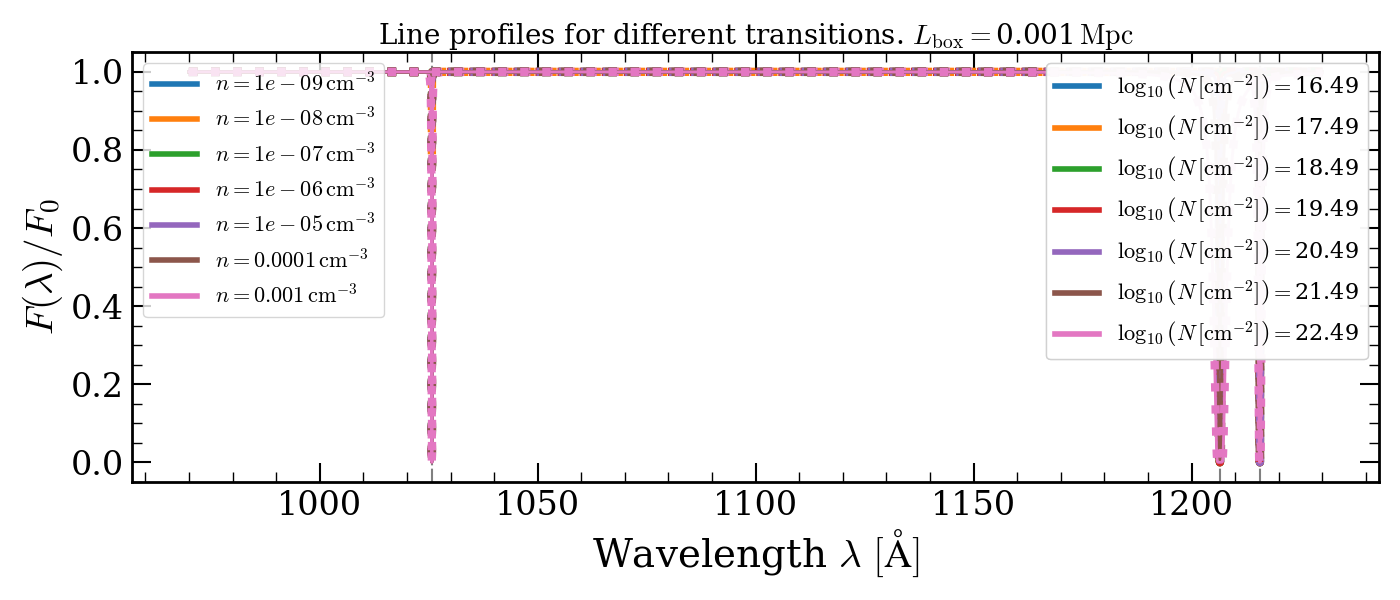

/home/dlopez/tmp/pip-tmp/ipykernel_32206/1565789425.py:73: RuntimeWarning: invalid value encountered in divide
  residual = F_over_F0_np[i_sp, i_sk, mask] / F_over_F0_analytic[i_sp, i_sk, mask] - 1


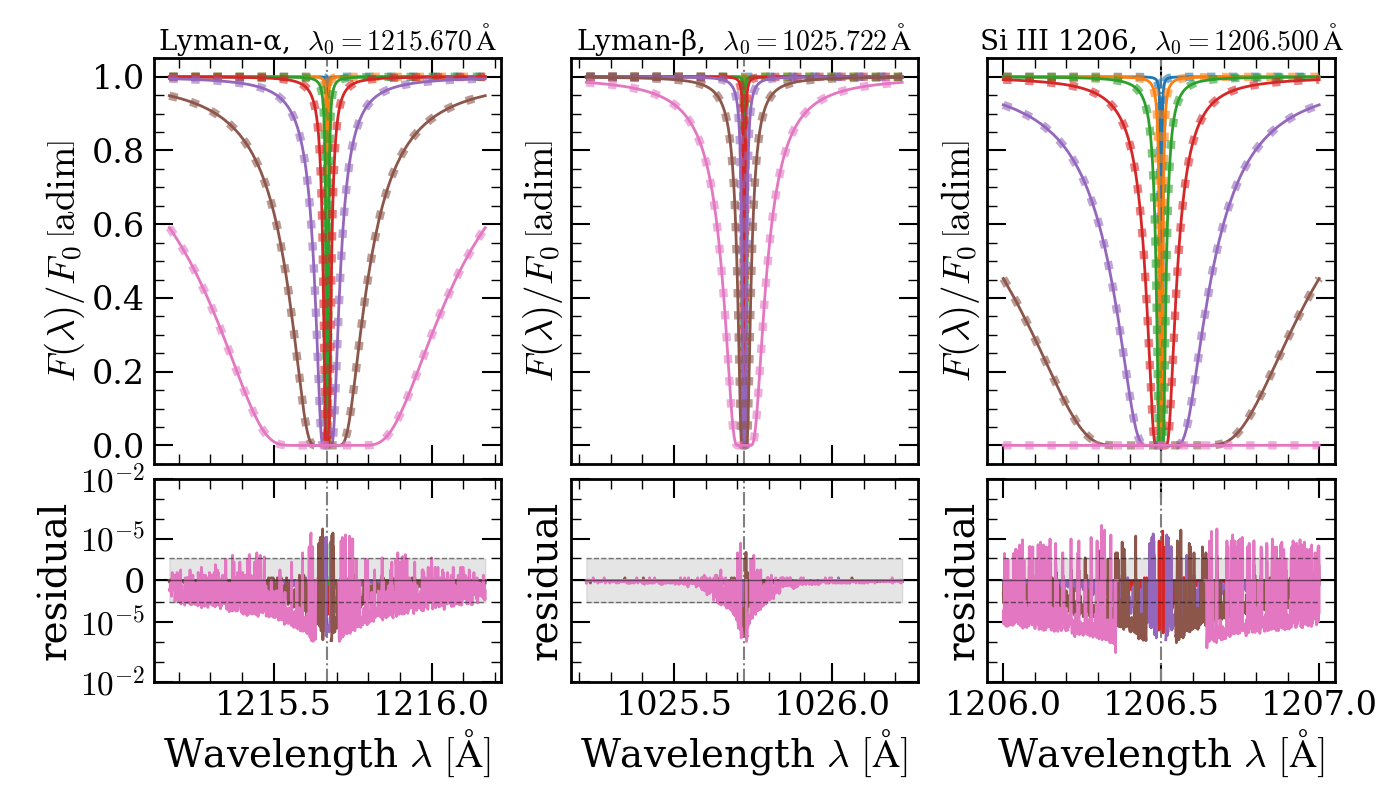

In [9]:
# Convert JAX arrays to NumPy for plotting
lambdas_np = np.asarray(wavelengths)           # (N_lambda,)
F_over_F0_np = np.asarray(F_over_F0)                           # (N_sp, N_sk, N_lambda)
F_over_F0_analytic = np.asarray(F_over_F0_analytic)            # (N_sp, N_sk, N_lambda)

colors = np.array(plt.cm.get_cmap("tab10").colors[:N_sk])

fig, ax = plt.subplots(figsize=(14, 6))

# Plot all profiles on the same axes
for i_sp, line in enumerate(line_bundle.lines):
    ax.axvline(line.lambda0_A, color="grey", linestyle="-.", linewidth=1.5, alpha=1.0)
    for i_sk in range(N_sk):
        ax.plot(lambdas_np, F_over_F0_np[i_sp, i_sk, :], color=colors[i_sk], linestyle='-', linewidth=2.0)
        ax.plot(lambdas_np, F_over_F0_analytic[i_sp, i_sk, :], color=colors[i_sk], linestyle=':', linewidth=6.0)

# Axes formatting
ax.set_xlabel(r"Wavelength $\lambda\ [\mathrm{\AA}]$")
ax.set_ylabel(r"$F(\lambda) / F_0$")
ax.set_title(r"Line profiles for different transitions. $L_{\mathrm{box}} = $" + str(L_box) + r"$\,\mathrm{Mpc}$", fontsize=20)



handles_n = []
handles_N = []
for i_sk in range(N_sk):
    _sampled_numbr_density_cm3 = fields.number_density(skewer_bundle.quadri_vectors[ii_cosmology][i_sk])[0, 0]
    _lbl = rf"$n = {_sampled_numbr_density_cm3:.2g} \, \mathrm{{cm^{{-3}}}}$"
    handles_n.append(Line2D([0], [0], color=colors[i_sk], lw=4, linestyle="-", label=_lbl))

    _quantity = jnp.log10(_sampled_numbr_density_cm3 * 1e6 * L_box * phys.Mpc_to_m)
    _lbl = r"$\log_{{10}} \left(N\, [\mathrm{{cm^{{-2}}}}] \right) =$" + str(round(_quantity, 2))
    handles_N.append(Line2D([0], [0], color=colors[i_sk], lw=4, linestyle="-", label=_lbl))

leg = ax.legend(handles=handles_n, loc="upper left", fontsize=16, ncols=1)
ax.add_artist(leg)
leg = ax.legend(handles=handles_N, loc="upper right", fontsize=16, ncols=1)
ax.add_artist(leg)

fig.tight_layout()
plt.show()




# Zoom half-width around each line center [Angstrom]
delta_lambda_A = 0.5   # adjust to taste
N_lines = line_bundle.n_lines
fig, axes = plt.subplots(
    nrows=2, ncols=N_lines, 
    figsize=(14, 8), 
    sharex='col',
    sharey='row',
    gridspec_kw=dict(height_ratios=[2, 1])
)

if N_lines == 1:
    axes = axes.reshape(2, 1)

for i_sp, (ax_main, ax_res, line) in enumerate(zip(axes[0], axes[1], line_bundle.lines)):
    lambda0 = line.lambda0_A
    
    mask = (lambdas_np >= lambda0 - delta_lambda_A) & (lambdas_np <= lambda0 + delta_lambda_A)
    lam_win = lambdas_np[mask]

    ax_main.axvline(lambda0, color="grey", linestyle="-.", linewidth=1.5)
    ax_res.axvline(lambda0, color="grey", linestyle="-.", linewidth=1.5)

    for i_sk in range(N_sk):
        ax_main.plot(lam_win, F_over_F0_np[i_sp, i_sk, mask], color=colors[i_sk], linestyle='-', linewidth=2.0)
        ax_main.plot(lam_win, F_over_F0_analytic[i_sp, i_sk, mask], color=colors[i_sk], linestyle=':', linewidth=6.0, alpha=0.6)

        residual = F_over_F0_np[i_sp, i_sk, mask] / F_over_F0_analytic[i_sp, i_sk, mask] - 1
        ax_res.plot(lam_win, residual, color=colors[i_sk], linestyle='-', linewidth=2.0)

    ax_main.set_title(rf"{line.name},  $\lambda_0 = {line.lambda0_A:.3f}\,\mathrm{{\AA}}$", fontsize=20)
    ax_main.set_ylabel(r"$F(\lambda) / F_0\, \left[\mathrm{adim}\right]$")
    ax_res.axhline(0.0, color="k", linewidth=1, alpha=0.5)
    ax_res.fill_between(lam_win, -1e-6, 1e-6, color="grey", alpha=0.2)
    ax_res.hlines(1e-6, xmin=lam_win[0], xmax=lam_win[-1], color="k", linewidth=1, linestyle='--', alpha=0.5)
    ax_res.hlines(-1e-6, xmin=lam_win[0], xmax=lam_win[-1], color="k", linewidth=1, linestyle='--', alpha=0.5)
    
    ax_res.set_xlabel(r"Wavelength $\lambda\ [\mathrm{\AA}]$")
    ax_res.set_ylabel("residual")
    ax_res.set_yscale("symlog", linthresh=1e-6)
    
    major_ticks = [-1e-2, -1e-5, 0.0, 1e-5, 1e-2]
    ax_res.set_yticks(major_ticks)
    ax_res.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(sjx.utils.plotting_tools.ten_power_formatter))
    ax_res.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())

fig.tight_layout()
fig.subplots_adjust(hspace=0.05, wspace=0.2)

plt.show()

# Check against analytical results varying scale factors

### Define wavelength range and lines to study

In [10]:
wavelengths = jnp.linspace(1200, 1220, 2**19)  # in Angstroms
line_bundle = sjx.constants.lines.LineBundle(["HI-LyA", "SiIII-1206"])

### Define fields

In [11]:
L_box = 5 # in Mpc

T0 = jnp.finfo(jnp.dtype('float32')).tiny
v0 = 0.0
n0 = 1e-7

fields = Fields({
    "HI": {
        "temperature": ScalarField(toy_samplers.temperature_sampler(T0_min=T0, T0_max=T0, L_box=L_box)),       # UNITS: [K]
        "velocity": VectorField(toy_samplers.velocity_sampler(v0_min=v0, v0_max=v0, L_box=L_box)),             # UNITS: [km/s]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),                                # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0)),                              # UNITS: [GHz]
        "number_density": ScalarField(toy_samplers.number_density_sampler(n0_min=n0, n0_max=n0, L_box=L_box)), # UNITS: [cm^-3]
    },
    "SiIII": {
        "temperature": ScalarField(toy_samplers.temperature_sampler(T0_min=T0, T0_max=T0, L_box=L_box)),       # UNITS: [K]
        "velocity": VectorField(toy_samplers.velocity_sampler(v0_min=v0, v0_max=v0, L_box=L_box)),             # UNITS: [km/s]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),                                # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0)),                              # UNITS: [GHz]
        "number_density": ScalarField(toy_samplers.number_density_sampler(n0_min=n0, n0_max=n0, L_box=L_box)), # UNITS: [cm^-3]
    }
})

### Define cosmology

In [12]:
# Create cosmology object
cosmology = Cosmology(
    H0=phys.H0,
    Omega_r_0=1.0,  # Radiation density (CMB + neutrinos)
    Omega_m_0=0.0,
    Omega_k_0=0.0,
    Omega_lambda_0=0.0,
)

### Define skewers

In [13]:
# create a skewer that go from x=0 to x=L_box with y=L_box/2 and z=L_box/2

N_sk = 2
N_ppsk = 92

_points = jnp.array([
    jnp.linspace(0.0, L_box, N_ppsk),
    L_box/2 * jnp.ones(N_ppsk),
    L_box/2 * jnp.ones(N_ppsk)
]).T

_points = jnp.tile(_points[None, ...], (N_sk, 1, 1))

In [14]:
skewer_bundle = SkewerBundle(
    spatial_points=_points,
    a0=[1.0, 0.99999976],                                      # scale factor at which ICs are defined
    x0=[0.0, 0.0],                                                # comoving distance at which ICs are defined, default: 0.0
    ICs_defined_at_index=[-1, 0],                                 # indices along the skewer where ICs are defined, (-1 means last point, 0 means first point), default: -1
    ICs_at_emission_or_absorption=["absorption", "emission"],     # whether the ICs are defined at emission or absorption, default: 'absorption'
    cosmologies=cosmology                                         # when manual_scale_factors are not provided, cosmologies must be defined
)

2026-01-12 09:30:10,495 - INFO - Initializing SkewerBundle with 2 skewers, 92 points per skewer
2026-01-12 09:30:10,555 - INFO - Using per-skewer ICs_defined_at_index: [-1  0]
2026-01-12 09:30:10,555 - INFO - Using per-skewer emission/absorption flags
2026-01-12 09:30:10,615 - INFO - Computing los_directions automatically from spatial coordinate differences
2026-01-12 09:30:10,925 - INFO - Computing comoving distances along skewer direction
2026-01-12 09:30:11,125 - INFO - Computing scale factors from cosmology
2026-01-12 09:30:12,126 - INFO - Storing quadri-vectors
2026-01-12 09:30:12,172 - INFO - SkewerBundle initialization complete


### Compute optical depth

In [15]:
optical_depth = od.compute_optical_depth(
    skewer_bundle,
    wavelengths,
    line_bundle,
    fields
)
F_over_F0 = jnp.exp(-optical_depth)

2026-01-12 09:30:12,246 - INFO - [OPTICAL_DEPTH] Starting computation for cosmology index 0, mode=pmap, Voigt impl=ExoJAX
2026-01-12 09:30:12,246 - INFO - [OPTICAL_DEPTH] Extracting 2 skewers with 92 points each
2026-01-12 09:30:12,298 - INFO - [OPTICAL_DEPTH] Computing line profiles for 2 lines across 2 species using pmap
2026-01-12 09:30:13,182 - INFO - Detected 1 device(s) for pmap.
2026-01-12 09:30:13,912 - INFO - [OPTICAL_DEPTH] Line profiles computed with shape (2, 2, 92, 524288)
2026-01-12 09:30:13,913 - INFO - [OPTICAL_DEPTH] Tiling fields for 2 species to line-level
2026-01-12 09:30:14,023 - INFO - [OPTICAL_DEPTH] Tiled number_density with shape (2, 2, 92)
2026-01-12 09:30:14,024 - INFO - [OPTICAL_DEPTH] Computing dtau_dx with constant 2.654009e-03 nm²/ns
2026-01-12 09:30:14,182 - INFO - [OPTICAL_DEPTH] dtau_dx computed with shape (2, 2, 92, 524288)
2026-01-12 09:30:14,183 - INFO - [OPTICAL_DEPTH] Reorienting 2 skewers based on photon path direction mask
2026-01-12 09:30:14,32

### Analytic benchmark

In [16]:
xem_Mpc = jnp.array([-L_box, 0.])
xf_Mpc  = jnp.array([0., L_box])

optical_depth_analytic = od.compute_optical_depth_analytical_radiation_domination(
    wavelengths,
    line_bundle.lambda0_A,
    line_bundle.A21_GHz,
    line_bundle.f_osc,
    skewer_bundle.a0,
    skewer_bundle.x0,
    xem_Mpc=xem_Mpc,
    xf_Mpc=xf_Mpc,
    n0_cm3=jnp.array([n0, n0])
)

F_over_F0_analytic = jnp.exp(-optical_depth_analytic)

### Validation plot

/home/dlopez/tmp/pip-tmp/ipykernel_32206/1123866010.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = np.array(plt.cm.get_cmap("tab10").colors[:N_sk])


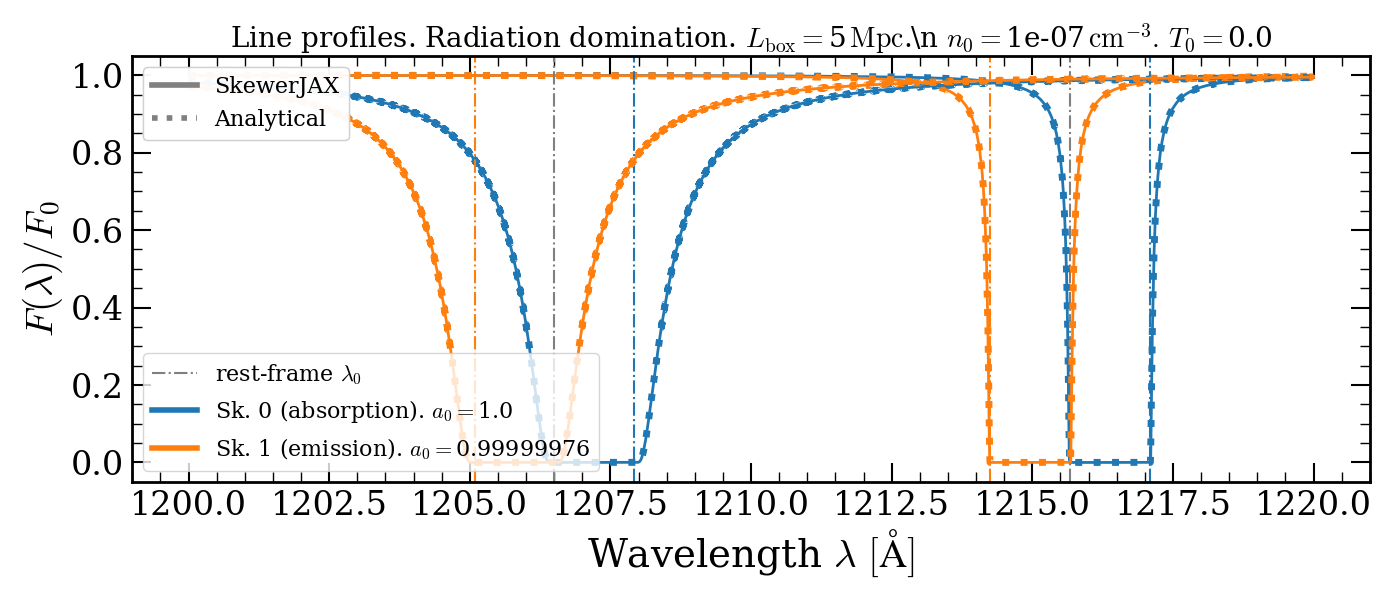

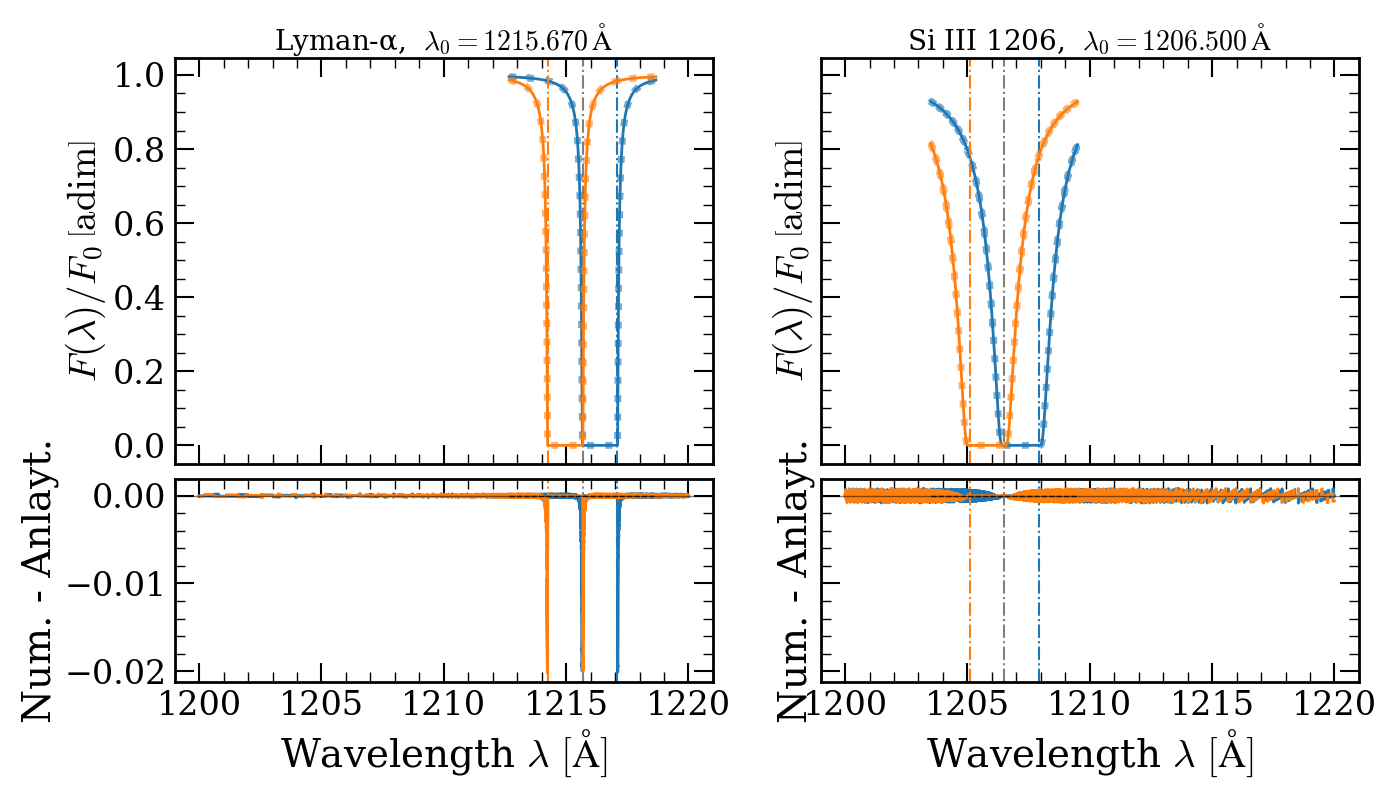

In [17]:
# Convert JAX arrays to NumPy for plotting
lambdas_np = np.asarray(wavelengths)                             # (N_lambda,)
F_over_F0_np = np.asarray(F_over_F0)                             # (N_sp, N_sk, N_lambda)
F_over_F0_analytic = np.asarray(F_over_F0_analytic)              # (N_sp, N_sk, N_lambda)

_indicies_final_array = jnp.where(skewer_bundle.ICs_defined_at_index == 0, -1, 0)

colors = np.array(plt.cm.get_cmap("tab10").colors[:N_sk])

fig, ax = plt.subplots(figsize=(14, 6))

# Plot all profiles on the same axes
handles = [Line2D([0], [0], color='grey', lw=1.5, linestyle='-.', label=r'rest-frame $\lambda_0$'),]
for i_sp, line in enumerate(line_bundle.lines):
    ax.axvline(line.lambda0_A, color="grey", linestyle="-.", linewidth=1.5, alpha=1.0)
    for i_sk in range(N_sk):
        _a0 = skewer_bundle.a0[i_sk]
        _af = skewer_bundle.quadri_vectors[ii_cosmology, i_sk, _indicies_final_array[i_sk], 0]
        ax.axvline(line.lambda0_A * _a0/_af, color=colors[i_sk], linestyle="-.", linewidth=1.5, alpha=1.0)

        ax.plot(lambdas_np, F_over_F0_np[i_sp, i_sk, :], color=colors[i_sk], linestyle='-', linewidth=2.0)
        ax.plot(lambdas_np, F_over_F0_analytic[i_sp, i_sk, :], color=colors[i_sk], linestyle=':', linewidth=5.0)

        _emission_or_absorption = "absorption" if skewer_bundle.is_absorption[i_sk] else "emission"
        if i_sp == 0:
            handles.append(Line2D([0], [0], color=colors[i_sk], lw=4, linestyle='-',
                label="Sk. " + str(i_sk) + " (" + _emission_or_absorption + r"). $a_0 = $" + str(skewer_bundle.a0[i_sk]) )
            )
legend = ax.legend(handles=handles, loc="lower left", fontsize=16, ncols=1)
ax.add_artist(legend)

handles = [
    Line2D([0], [0], color='grey', lw=4, linestyle='-', label='SkewerJAX'),
    Line2D([0], [0], color='grey', lw=4, linestyle=':', label='Analytical')
]
legend = ax.legend(handles=handles, loc="upper left", fontsize=16, ncols=1)
ax.add_artist(legend)

# Axes formatting
ax.set_xlabel(r"Wavelength $\lambda\ [\mathrm{\AA}]$")
ax.set_ylabel(r"$F(\lambda) / F_0$")
ax.set_title(r"Line profiles. Radiation domination. $L_{\mathrm{box}} = $" + str(L_box) + r"$\,\mathrm{Mpc}$.\n $n_0 = $" + str(n0) + r"$\,\mathrm{cm}^{-3}.\, T_0 = $" + str(round(T0, 4)), fontsize=20)

fig.tight_layout()
plt.show()



# Zoom half-width around each line center [Angstrom]
delta_lambda_A = 3.0   # adjust to taste
N_lines = line_bundle.n_lines

fig, axes = plt.subplots(
    nrows=2, ncols=N_lines, figsize=(14, 8), sharex='col', sharey='row', gridspec_kw=dict(height_ratios=[2, 1])
)

if N_lines == 1:
    axes = axes.reshape(2, 1)


for i_sp, (ax_main, ax_res, line) in enumerate(zip(axes[0], axes[1], line_bundle.lines)):
    lambda0 = line.lambda0_A
  
    mask = (lambdas_np >= lambda0 - delta_lambda_A) & (lambdas_np <= lambda0 + delta_lambda_A)
    lam_win = lambdas_np[mask]
    ax_main.axvline(lambda0, color="grey", linestyle="-.", linewidth=1.5)
    ax_res.axvline(lambda0, color="grey", linestyle="-.", linewidth=1.5)

    for i_sk in range(N_sk):
        _a0 = skewer_bundle.a0[i_sk]
        _af = skewer_bundle.quadri_vectors[ii_cosmology, i_sk, _indicies_final_array[i_sk], 0]
        ax_main.axvline(line.lambda0_A * _a0/_af, color=colors[i_sk], linestyle="-.", linewidth=1.5, alpha=1.0)
        ax_res.axvline(line.lambda0_A * _a0/_af, color=colors[i_sk], linestyle="-.", linewidth=1.5, alpha=1.0)

        ax_main.plot(lam_win, F_over_F0_np[i_sp, i_sk, mask], color=colors[i_sk], linestyle='-', linewidth=2.0)
        ax_main.plot(lam_win, F_over_F0_analytic[i_sp, i_sk, mask], color=colors[i_sk], linestyle=':', linewidth=5.0, alpha=0.6)

        # Compute residual
        residual = F_over_F0_np[i_sp, i_sk] - F_over_F0_analytic[i_sp, i_sk]
        ax_res.plot(lambdas_np, residual, color=colors[i_sk], linestyle='-', linewidth=2.0)

    ax_main.set_title(rf"{line.name},  $\lambda_0 = {line.lambda0_A:.3f}\,\mathrm{{\AA}}$", fontsize=20)
    ax_main.set_ylabel(r"$F(\lambda) / F_0\, \left[\mathrm{adim}\right]$")
    ax_res.axhline(0.0, color="k", linewidth=1, alpha=0.5)
    ax_res.fill_between(lam_win, -1e-6, 1e-6, color="grey", alpha=0.2)
    ax_res.hlines(1e-6, xmin=lam_win[0], xmax=lam_win[-1], color="k", linewidth=1, linestyle='--', alpha=0.5)
    ax_res.hlines(-1e-6, xmin=lam_win[0], xmax=lam_win[-1], color="k", linewidth=1, linestyle='--', alpha=0.5)
  
    ax_res.set_xlabel(r"Wavelength $\lambda\ [\mathrm{\AA}]$")
    ax_res.set_ylabel("Num. - Anlayt.")
    # ax_res.set_yscale("symlog", linthresh=1e-1)
  
    # major_ticks = [-1e-1, -1e-5, 0.0, 1e-5, 1e-1]
    # ax_res.set_yticks(major_ticks)
    # ax_res.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(sjx.utils.plotting_tools.ten_power_formatter))
    # ax_res.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())

fig.tight_layout()
fig.subplots_adjust(hspace=0.05, wspace=0.2)
plt.show()

# Check variations with temperature and LoS velocity

### Define wavelength range and lines to study

In [18]:
wavelengths = jnp.linspace(970, 1230, 2**19)  # in Angstroms
line_bundle = sjx.constants.lines.LineBundle(["HI-LyA", "HI-LyB", "SiIII-1206"])

### Define Fields

In [19]:
L_box = 1e-3

n0 = 1e-5

fields = Fields({
    "HI": {
        "temperature": ScalarField(toy_samplers.temperature_sampler(T0_min=1e1, T0_max=1e7, L_box=L_box)),
        "velocity": VectorField(toy_samplers.velocity_sampler(v0_min=-0., v0_max=0., L_box=L_box)),
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0)),
        "number_density": ScalarField(toy_samplers.number_density_sampler(n0_min=n0, n0_max=n0, L_box=L_box)),
    },
    "SiIII": {
        "temperature": ScalarField(toy_samplers.temperature_sampler(T0_min=1e1, T0_max=1e7, L_box=L_box)),
        "velocity": VectorField(toy_samplers.velocity_sampler(v0_min=-0., v0_max=0., L_box=L_box)),
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0)),
        "number_density": ScalarField(toy_samplers.number_density_sampler(n0_min=n0, n0_max=n0, L_box=L_box)),
    }
})

### Define Skewers

In [20]:
N_sk = 7
N_ppsk = 32

_points        = aux.make_plane_points(L_box, 'y', L_box/2, N_sk, N_ppsk)
skewer_bundle = SkewerBundle(
    spatial_points=_points,
    a0=1.0,                                                      # scale factor at which ICs are defined, default: 1.0
    x0=0.0,                                                      # comoving distance at which ICs are defined, default: 0.0
    ICs_defined_at_index=-1,                                     # indices along the skewer where ICs are defined, (-1 means last point, 0 means first point), default: -1
    ICs_at_emission_or_absorption="absorption",                  # whether the ICs are defined at emission or absorption, default: 'absorption'
    los_directions=None,                                         # Let SkewerBundle compute los_directions automatically
    manual_scale_factors=jnp.ones_like(_points[None, ..., 0]),   # if provided, must have shape (N_cosmologies, N_skewers, N_points_per_skewer)
    cosmologies=None                                             # when the manual scale factors are not provided, cosmologies must be defined
)

2026-01-12 09:30:16,479 - INFO - Initializing SkewerBundle with 7 skewers, 32 points per skewer
2026-01-12 09:30:16,480 - INFO - Broadcasting scalar ICs_defined_at_index=-1 to all 7 skewers
2026-01-12 09:30:16,480 - INFO - All skewers set to absorption mode
2026-01-12 09:30:16,480 - INFO - Computing los_directions automatically from spatial coordinate differences
2026-01-12 09:30:16,485 - INFO - Computing comoving distances along skewer direction
2026-01-12 09:30:16,487 - INFO - Using provided scale factors (bypassing auto-calculation)
2026-01-12 09:30:16,488 - INFO - Storing quadri-vectors
2026-01-12 09:30:16,488 - INFO - SkewerBundle initialization complete


### Compute Optical Depth

In [21]:
optical_depth = od.compute_optical_depth(
    skewer_bundle,
    wavelengths,
    line_bundle,
    fields,
    compute_mode="vmap",
    num_gpus=None
)
F_over_F0 = jnp.exp(-optical_depth)

2026-01-12 09:30:16,647 - INFO - [OPTICAL_DEPTH] Starting computation for cosmology index 0, mode=vmap, Voigt impl=ExoJAX
2026-01-12 09:30:16,648 - INFO - [OPTICAL_DEPTH] Extracting 7 skewers with 32 points each
2026-01-12 09:30:16,649 - INFO - [OPTICAL_DEPTH] Computing line profiles for 3 lines across 2 species using vmap
2026-01-12 09:30:17,011 - INFO - [OPTICAL_DEPTH] Line profiles computed with shape (3, 7, 32, 524288)
2026-01-12 09:30:17,011 - INFO - [OPTICAL_DEPTH] Tiling fields for 2 species to line-level
2026-01-12 09:30:17,022 - INFO - [OPTICAL_DEPTH] Tiled number_density with shape (3, 7, 32)
2026-01-12 09:30:17,022 - INFO - [OPTICAL_DEPTH] Computing dtau_dx with constant 2.654009e-03 nm²/ns
2026-01-12 09:30:17,096 - INFO - [OPTICAL_DEPTH] dtau_dx computed with shape (3, 7, 32, 524288)
2026-01-12 09:30:17,097 - INFO - [OPTICAL_DEPTH] Reorienting 7 skewers based on photon path direction mask
2026-01-12 09:30:17,138 - INFO - [OPTICAL_DEPTH] Arrays reoriented: quadri_vectors (7,

/home/dlopez/tmp/pip-tmp/ipykernel_32206/696064770.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = np.array(plt.cm.get_cmap("tab10").colors[:N_sk])


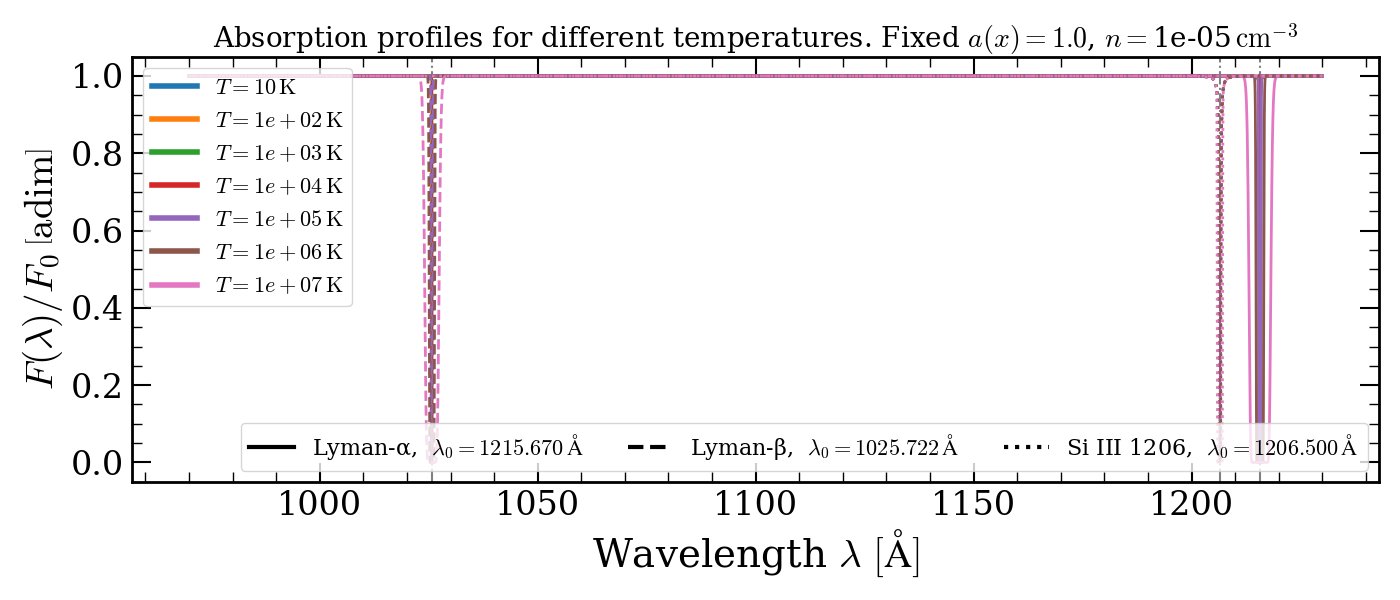

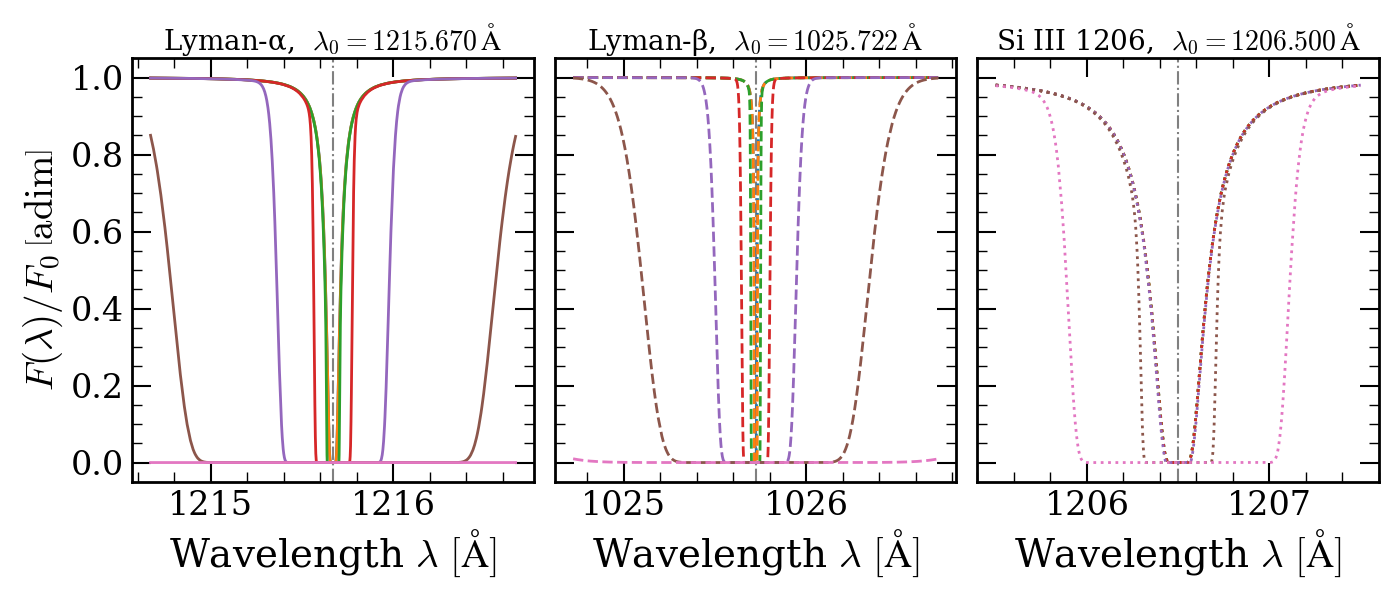

In [22]:
# Convert JAX arrays to NumPy for plotting
lambdas_np = np.asarray(wavelengths)           # (N_lambda,)
F_over_F0_np = np.asarray(F_over_F0)                           # (N_sp, N_sk, N_lambda)

colors = np.array(plt.cm.get_cmap("tab10").colors[:N_sk])
linestyles = ['-', '--', ':']

fig, ax = plt.subplots(figsize=(14, 6))

# Plot all profiles on the same axes
for i_sp, line in enumerate(line_bundle.lines):
    ax.axvline(line.lambda0_A, color="grey", linestyle="-.", linewidth=1.5, alpha=1.0)
    ls = linestyles[i_sp % len(linestyles)]
    for i_sk in range(N_sk):
        ax.plot(lambdas_np, F_over_F0_np[i_sp, i_sk, :], color=colors[i_sk], linestyle=ls, linewidth=2.0)

# Axes formatting
ax.set_xlabel(r"Wavelength $\lambda\ [\mathrm{\AA}]$")
ax.set_ylabel(r"$F(\lambda) / F_0\, \left[\mathrm{adim}\right]$")
ax.set_title(r"Absorption profiles for different temperatures. Fixed $a(x)=1.0$, $n=$" + str(n0) + r"$\,\mathrm{cm}^{-3}$", fontsize=20)

temp_handles = []
for i_sk in range(N_sk):
    _sampled_T = fields.temperature(skewer_bundle.quadri_vectors[ii_cosmology][i_sk])
    lbl = rf"$T = {_sampled_T[0, 0]:.2g}\,\mathrm{{K}}$"
    temp_handles.append(Line2D([0], [0], color=colors[i_sk], lw=4, linestyle="-", label=lbl))
leg_T = ax.legend(handles=temp_handles, loc="upper left", fontsize=16, ncols=1)
ax.add_artist(leg_T)


# Legend for lines (linestyles)
line_handles = []
for i_sp, line in enumerate(line_bundle.lines):
    ls = linestyles[i_sp % len(linestyles)]
    lbl = rf"{line.name},  $\lambda_0 = {line.lambda0_A:.3f}\,\mathrm{{\AA}}$"
    line_handles.append(Line2D([0], [0], color="k", lw=3, linestyle=ls, label=lbl))
leg_L = ax.legend(handles=line_handles, loc="lower right", fontsize=16, ncol=line_bundle.n_lines)

fig.tight_layout()
plt.show()



# Zoom half-width around each line center [Angstrom]
delta_lambda_A = 1.0   # adjust to taste
fig, axes = plt.subplots(nrows=1, ncols=line_bundle.n_lines, figsize=(14, 6), sharex=False, sharey=True)
if line_bundle.n_lines == 1:
    axes = [axes]  # in case N_sp=1, make it iterable

for i_sp, (ax, line) in enumerate(zip(axes, line_bundle.lines)):
    lambda0 = line.lambda0_A
    ax.axvline(lambda0, color="grey", linestyle="-.", linewidth=1.5)
    mask = (lambdas_np >= lambda0 - delta_lambda_A) & (lambdas_np <= lambda0 + delta_lambda_A)
    lam_win = lambdas_np[mask]  # (N_lambda_window,)

    # Plot each temperature (each skewer)
    for i_sk in range(N_sk):
        ax.plot(lam_win, F_over_F0_np[i_sp, i_sk, mask], color=colors[i_sk], linestyle=linestyles[i_sp], linewidth=2.0)

    # Panel title and scaling
    ax.set_title(rf"{line.name},  $\lambda_0 = {line.lambda0_A:.3f}\,\mathrm{{\AA}}$", fontsize=20)
    ax.set_xlabel(r"Wavelength $\lambda\ [\mathrm{\AA}]$")

axes[0].set_ylabel(r"$F(\lambda) / F_0\, \left[\mathrm{adim}\right]$")
fig.tight_layout()
plt.show()

# Resolution study

In [23]:
line_bundle = sjx.constants.lines.LineBundle(["HI-LyA"])

In [24]:
# Create cosmology object
cosmology = Cosmology(
    H0=phys.H0,
    Omega_r_0=1.0,  # Radiation density (CMB + neutrinos)
    Omega_m_0=0.0,
    Omega_k_0=0.0,
    Omega_lambda_0=0.0,
)

In [25]:
L_box = 1 # in Mpc

T0 = jnp.finfo(jnp.dtype('float32')).tiny
v0 = 0.0

fields = Fields({
    "HI": {
        "temperature": ScalarField(toy_samplers.temperature_sampler(T0_min=T0, T0_max=T0, L_box=L_box)),            # UNITS: [K]
        "velocity": VectorField(toy_samplers.velocity_sampler(v0_min=v0, v0_max=v0, L_box=L_box)),                  # UNITS: [km/s]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),                                     # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0)),                                   # UNITS: [GHz]
        "number_density": ScalarField(toy_samplers.number_density_sampler(n0_min=1e-9, n0_max=4e-9, L_box=L_box)),  # UNITS: [cm^-3]
    }
})

In [26]:
N_sk = 2

In [27]:
_delta = 0.35 # [Angstrom]
wavelengths = jnp.linspace(line_bundle.lambda0_A[0]-6e-2, line_bundle.lambda0_A[0]+_delta, 2**18)  # in Angstroms

N_resolution_ppsk = 2
array_N_ppsk = jnp.linspace(16, 31, N_resolution_ppsk).astype(jnp.int32)

F_over_F0 = []
for ii_N_ppsk, N_ppsk in enumerate(array_N_ppsk):

    _points        = aux.make_plane_points(L_box, 'x', L_box/2, N_sk, N_ppsk)
    skewer_bundle = SkewerBundle(
        spatial_points=_points,
        a0=1.0,                                                      # scale factor at which ICs are defined, default: 1.0
        x0=0.0,                                                      # comoving distance at which ICs are defined, default: 0.0
        ICs_defined_at_index=-1,                                     # indices along the skewer where ICs are defined, (-1 means last point, 0 means first point), default: -1
        ICs_at_emission_or_absorption="absorption",                  # whether the ICs are defined at emission or absorption, default: 'absorption'
        cosmologies=cosmology                                        # when the manual scale factors are not provided, cosmologies must be defined
    )

    optical_depth = od.compute_optical_depth(
        skewer_bundle,
        wavelengths,
        line_bundle,
        fields,
        compute_mode="vmap",
        num_gpus=None
    )
    F_over_F0.append(jnp.exp(-optical_depth))

F_over_F0 = jnp.stack(F_over_F0, axis=0)
print(F_over_F0.shape) # (N_resolution_ppsk, N_lines, N_sk, N_lambda)

2026-01-12 09:30:19,370 - INFO - Initializing SkewerBundle with 2 skewers, 16 points per skewer
2026-01-12 09:30:19,388 - INFO - Broadcasting scalar ICs_defined_at_index=-1 to all 2 skewers
2026-01-12 09:30:19,404 - INFO - All skewers set to absorption mode
2026-01-12 09:30:19,421 - INFO - Computing los_directions automatically from spatial coordinate differences
2026-01-12 09:30:19,610 - INFO - Computing comoving distances along skewer direction
2026-01-12 09:30:19,746 - INFO - Computing scale factors from cosmology
2026-01-12 09:30:20,555 - INFO - Storing quadri-vectors
2026-01-12 09:30:20,602 - INFO - SkewerBundle initialization complete
2026-01-12 09:30:20,603 - INFO - [OPTICAL_DEPTH] Starting computation for cosmology index 0, mode=vmap, Voigt impl=ExoJAX
2026-01-12 09:30:20,603 - INFO - [OPTICAL_DEPTH] Extracting 2 skewers with 16 points each
2026-01-12 09:30:20,658 - INFO - [OPTICAL_DEPTH] Computing line profiles for 1 lines across 1 species using vmap
2026-01-12 09:30:21,675 - 

(2, 1, 2, 262144)


In [28]:

optical_depth_analytic = od.compute_optical_depth_analytical_radiation_domination(
    wavelengths,
    line_bundle.lambda0_A,
    line_bundle.A21_GHz,
    line_bundle.f_osc,
    skewer_bundle.a0,
    skewer_bundle.x0,
    xem_Mpc=-L_box * jnp.ones(N_sk),
    xf_Mpc=jnp.zeros(N_sk),
    n0_cm3=fields.number_density(skewer_bundle.quadri_vectors[ii_cosmology])[0, :, 0]
)

F_over_F0_analytic = jnp.exp(-optical_depth_analytic)

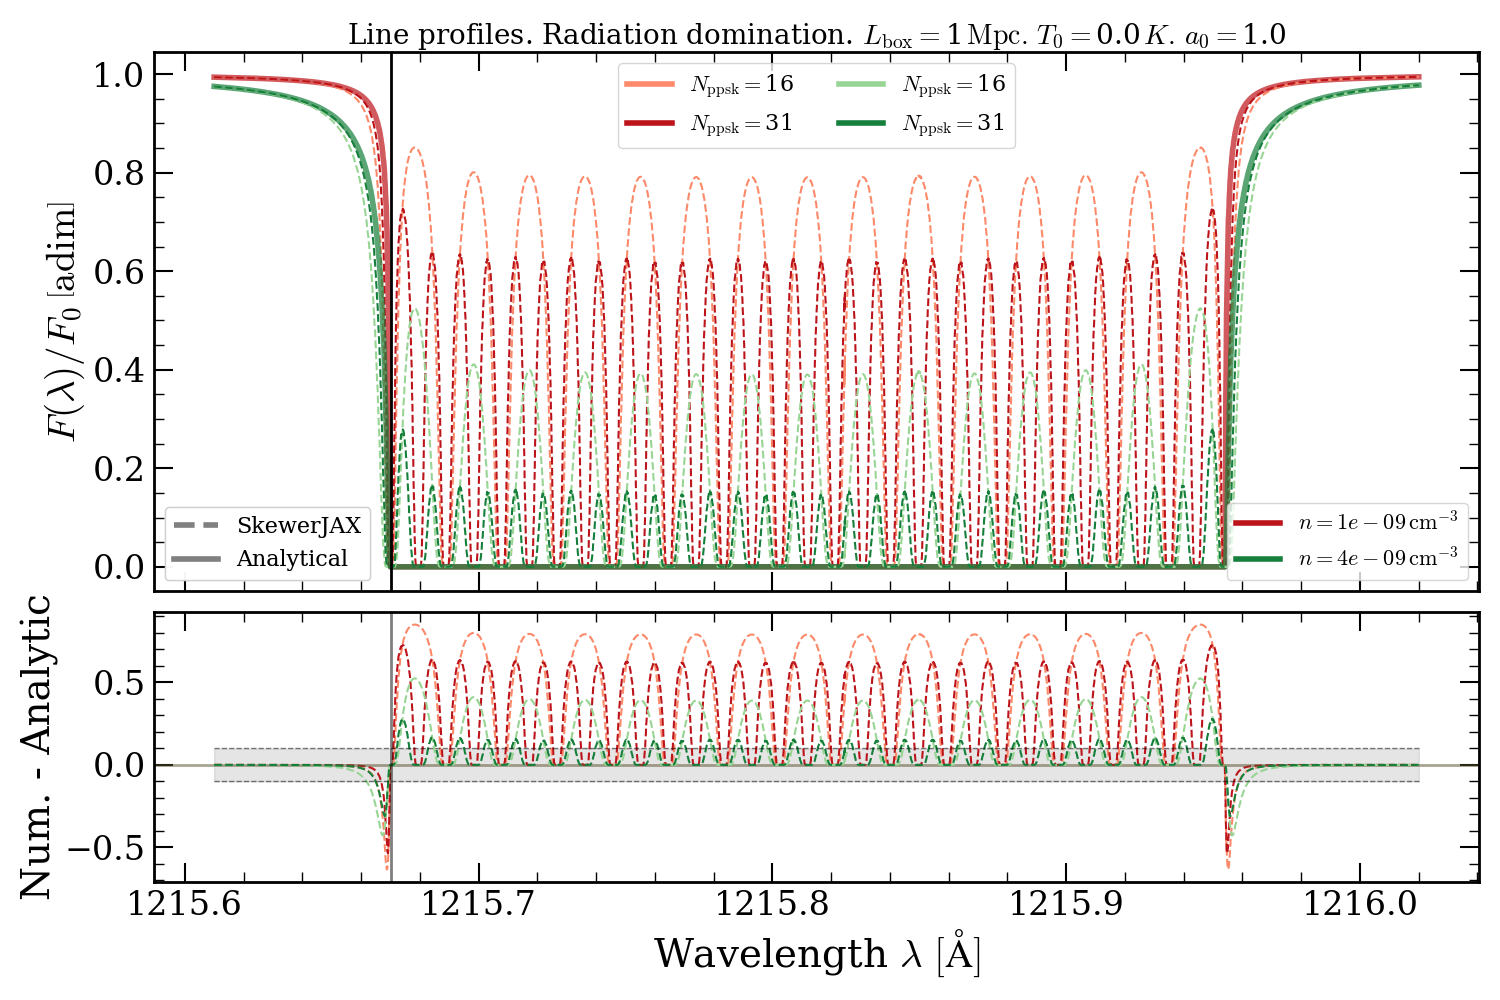

In [33]:
# Convert JAX arrays to NumPy for plotting
lambdas_np = np.asarray(wavelengths)                             # (N_lambda,)
F_over_F0_np = np.asarray(F_over_F0)                             # (resolution N_ppsk, N_lines, N_sk, N_lambda)

colors = np.array([
    plt.cm.Reds(np.linspace(0.4, 0.8, N_resolution_ppsk)),
    plt.cm.Greens(np.linspace(0.4, 0.8, N_resolution_ppsk))
])

# Create figure with two subplots (top: original, bottom: residuals)
fig, (ax_top, ax_res) = plt.subplots(2, 1, figsize=(15, 10), 
                                      height_ratios=[2, 1], 
                                      sharex=True)

# Plot all profiles on the same axes in top panel
handles_colors = []
handles_N_ppsk = []
for i_sp, line in enumerate(line_bundle.lines):
    for i_sk in range(N_sk):
        ax_top.plot(lambdas_np, F_over_F0_analytic[i_sp, i_sk, :], color=colors[i_sk][-1], linewidth=4.0, linestyle='-', alpha=0.7)
        for i_ppsk, N_ppsk in enumerate(array_N_ppsk):
            ax_top.plot(lambdas_np, F_over_F0_np[i_ppsk, i_sp, i_sk, :], color=colors[i_sk, i_ppsk], linewidth=1.5, linestyle='--')

            if i_sp == 0:
                _lbl = r"$N_\mathrm{ppsk} =$" + str(round(N_ppsk, 2))
                handles_N_ppsk.append(Line2D([0], [0], color=colors[i_sk, i_ppsk], lw=4, linestyle="-", label=_lbl))
        
        if i_sp == 0:
            _sampled_numbr_density_cm3 = fields.number_density(skewer_bundle.quadri_vectors[ii_cosmology])[i_sp, i_sk, 0]
            _lbl = rf"$n = {_sampled_numbr_density_cm3:.2g} \, \mathrm{{cm^{{-3}}}}$"
            handles_colors.append(Line2D([0], [0], color=colors[i_sk][-1], lw=4, linestyle="-", label=_lbl))

        # Plot analytic reference line at zero
        if i_sp == 0:
            ax_res.axhline(y=0, color=colors[i_sk][-1], linestyle='-', linewidth=2.0, alpha=0.3)
        
        for i_ppsk, N_ppsk in enumerate(array_N_ppsk):
            residual = F_over_F0_np[i_ppsk, i_sp, i_sk] - F_over_F0_analytic[i_sp, i_sk]
            ax_res.plot(lambdas_np, residual, color=colors[i_sk, i_ppsk], linestyle='--', linewidth=1.5)

    ax_top.axvline(line.lambda0_A, color="k", linestyle="-", linewidth=2., alpha=1.0)

    # Add vertical line at line center
    ax_res.axvline(line.lambda0_A, color="k", linestyle="-", linewidth=2., alpha=0.5)

# Legends for top panel (keeping your original legend code)
leg = ax_top.legend(handles=handles_colors, loc="lower right", fontsize=16, ncols=1)
ax_top.add_artist(leg)

leg = ax_top.legend(handles=handles_N_ppsk, loc="upper center", fontsize=16, ncols=len(array_N_ppsk))
ax_top.add_artist(leg)

handles_linestyles = [
    Line2D([0], [0], color="grey", lw=4, linestyle="--", label="SkewerJAX"),
    Line2D([0], [0], color="grey", lw=4, linestyle="-", label="Analytical")
]
leg = ax_top.legend(handles=handles_linestyles, loc="lower left", fontsize=16, ncols=1)
ax_top.add_artist(leg)

ax_res.fill_between(lambdas_np, 0.1, -0.1, color="grey", alpha=0.2)
ax_res.hlines(0.1, xmin=lambdas_np[0], xmax=lambdas_np[-1], color="k", linewidth=1, linestyle='--', alpha=0.5)
ax_res.hlines(-0.1, xmin=lambdas_np[0], xmax=lambdas_np[-1], color="k", linewidth=1, linestyle='--', alpha=0.5)

# Axes formatting for top panel
ax_top.set_ylabel(r"$F(\lambda) / F_0\, \left[\mathrm{adim}\right]$")

# Axes formatting for residual panel
ax_res.set_xlabel(r"Wavelength $\lambda\ [\mathrm{\AA}]$")
ax_res.set_ylabel(r"Num. - Analytic")

ax_top.set_title(r"Line profiles. Radiation domination." + r" $L_\mathrm{box} = $" + str(L_box) + r"$\,\mathrm{Mpc}.\, T_0 = $" + str(round(T0, 4)) + r"$\, K.\, a_0 = $" + str(round(skewer_bundle.a0[0], 4)), fontsize=20)

# Adjust layout
fig.tight_layout()
plt.show()

# tests to explore vmap, pmap and Pytrees

In [30]:
from jax import vmap, jit, pmap
import jax.numpy as jnp
import matplotlib.pyplot as plt



def make_chi2_computer(model_fn):
    """Factory: model_fn is baked into the returned function."""
    def chi2(data, params):
        model = model_fn(data["x"], params)
        return jnp.sum((data["y"] - model)**2 / data["noise"]**2)
    return chi2

def sinusoid_model(x, params):
    return params["amp"] * jnp.sin(x + params["phase"])


chi2_sinusoid = make_chi2_computer(sinusoid_model)



# Each sightline is a dict of arrays shape (n_points,)
datasets = {
    "x": jnp.array([
        [0.0, 0.5, 1.0, 1.5, 2.0],  # Sightline 0
        [0.0, 0.7, 1.4, 2.1, 2.8],  # Sightline 1
        [0.0, 1.0, 2.0, 3.0, 4.0],  # Sightline 2
    ]),
    "y": jnp.array([
        [0.1, 0.9, 0.2, -0.7, -0.3],  # Observed flux for sightline 0
        [0.0, 0.5, 0.8, 0.3, -0.5],   # Sightline 1
        [0.1, 1.2, 0.9, 0.4, 0.1],    # Sightline 2
    ]),
    "noise": jnp.full((3, 5), 0.05)  # Constant noise for all
}

params_sine = {"amp": 1.0, "phase": 0.0}




vcompute_sinusoid = vmap(chi2_sinusoid, in_axes=(0, None))
chi2_vmap = vcompute_sinusoid(datasets, params_sine)
print(chi2_vmap)

[1976.9028   427.84015  375.90353]


In [31]:
import jax

In [32]:
# Simulate 8 GPUs (use real number if available)
n_devices = min(8, jax.local_device_count())
print(f"Available devices: {jax.local_device_count()}, Using: {n_devices}")

# Reshape data: (n_devices, n_sightlines_per_device, ...)
# Pad to multiple of n_devices if needed
n_total = datasets["x"].shape[0]
if n_total % n_devices != 0:
    pad_size = n_devices - (n_total % n_devices)
    datasets = {k: jnp.pad(v, ((0, pad_size), (0, 0))) for k, v in datasets.items()}

datasets_sharded = {
    k: jnp.reshape(v, (n_devices, -1, v.shape[-1])) 
    for k, v in datasets.items()
}
print(f"Sharded shape: {datasets_sharded['x'].shape}")  # (8, 1, 5) if 8 devices

# Create pmapped pipeline
# pmap the vmapped function: one per device
pcompute_sinusoid = pmap(
    vcompute_sinusoid,  # Re-use the vmapped version
    in_axes=(0, None),  # Shard the dataset axis 0, broadcast params
    axis_name="devices"
)

# Run on all devices
chi2_pmap = pcompute_sinusoid(datasets_sharded, params_sine)
print(f"PMAP χ² (sharded): {chi2_pmap}")  # shape: (8, 1)
print(f"PMAP χ² (flattened): {chi2_pmap.flatten()[:n_total]}")

Available devices: 1, Using: 1
Sharded shape: (1, 3, 5)
PMAP χ² (sharded): [[1976.9028   427.84015  375.90353]]
PMAP χ² (flattened): [1976.9028   427.84015  375.90353]
